# EDA CEDR-M7

Русские тексты с эмоциями, 7 классов. [Источник](https://huggingface.co/datasets/Aniemore/cedr-m7), лицензия MIT.

## Библиотеки

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data/raw/cedr-m7'

## Загрузка

Скачиваем train и test с Hugging Face, если их ещё нет.

In [2]:
if not (DATA / 'train.csv').exists():
    from huggingface_hub import hf_hub_download
    DATA.mkdir(parents=True, exist_ok=True)
    for split in ['train', 'test']:
        path = hf_hub_download('Aniemore/cedr-m7', f'data/{split}-00000-of-00001.parquet', repo_type='dataset',
                               revision='7c72eb7322a00b531365e678bad8bba77e4bc8e3')
        part = pd.read_parquet(path)
        part['labels'] = part['labels'].map(';'.join)
        part[['text', 'labels', 'source']].to_csv(DATA / f'{split}.csv', index_label='id')

df = pd.concat([pd.read_csv(DATA / f'{split}.csv').assign(split=split) for split in ['train', 'test']],
               ignore_index=True)
print(df['split'].value_counts().to_dict())
df.head()

{'train': 7528, 'test': 1882}


,id,text,labels,source,split
0,cedr_train_0,Суровый гималайский медведь .,neutral,lj,train
1,cedr_train_1,"Так, обнаружено несколько проблем с дисплеем (...",neutral,lenta,train
2,cedr_train_2,У меня остается только один вопрос - является ...,enthusiasm,lj,train
3,cedr_train_3,Забавно как люди в возрасте удивляются входящи...,happiness,twitter,train
4,cedr_train_4,"Издание The Register отмечает, что у владельце...",neutral,lenta,train


## Пропуски и повторы

Повторы ищем без учёта регистра и пунктуации.

In [3]:
df['clean'] = df['text'].str.lower().str.replace(r'[^\w\s]', '', regex=True).str.split().str.join(' ')
train_texts = df[df['split'] == 'train']['clean']

print('Пропуски:', df['text'].isna().sum())
print('Тексты с двумя метками:', df['labels'].str.contains(';').sum())
print('Повторы:', df['clean'].duplicated().sum())
print('Повторы с разными метками:', (df.groupby('clean')['labels'].nunique() > 1).sum())
print('Тексты test, которые есть в train:', df[df['split'] == 'test']['clean'].isin(train_texts).sum())

Пропуски: 0
Тексты с двумя метками: 108
Повторы: 51
Повторы с разными метками: 4
Тексты test, которые есть в train: 14


## Классы

Дальше берём только тексты с одной меткой.

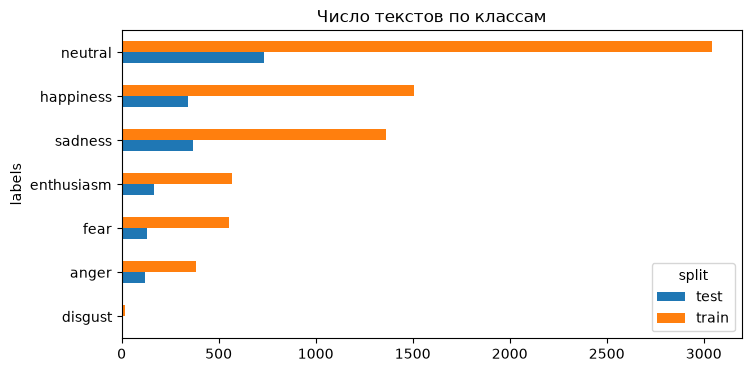

split,test,train
labels,,
neutral,734,3043
happiness,341,1508
sadness,368,1365
enthusiasm,165,568
fear,133,553
anger,121,384
disgust,3,16


In [4]:
single = df[~df['labels'].str.contains(';')].copy()
counts = pd.crosstab(single['labels'], single['split']).sort_values('train')
counts.plot.barh(figsize=(8, 4), title='Число текстов по классам')
plt.show()
counts.sort_values('train', ascending=False)

## Источники

`lenta`: новости, `lj`: блоги LiveJournal, `twitter`: твиты.

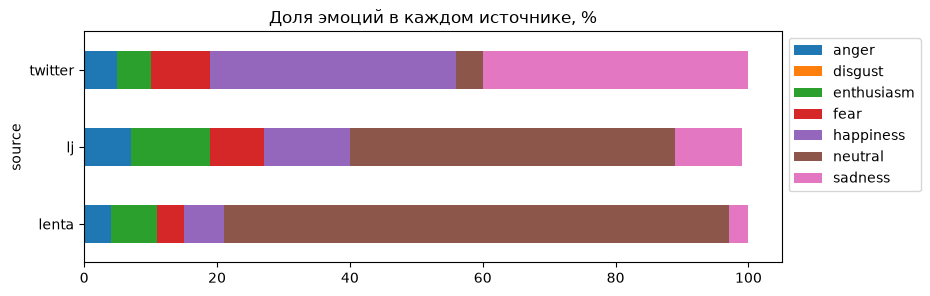

Доля текстов с пробелом перед . , ! ?
source
lenta      0.00
lj         1.00
twitter    0.05
Name: text, dtype: float64


In [5]:
by_source = pd.crosstab(single['source'], single['labels'], normalize='index').round(2) * 100
by_source.plot.barh(stacked=True, figsize=(9, 3), title='Доля эмоций в каждом источнике, %')
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

print('Доля текстов с пробелом перед . , ! ?')
print(df['text'].str.contains(r' [.,!?]').groupby(df['source']).mean().round(2))

## Что значит enthusiasm

В исходном CEDR такого класса нет, есть surprise (удивление). Проверяем слова удивления.

In [6]:
surprise = single['text'].str.lower().str.contains('удив|странн|неожидан')
surprise.groupby(single['labels']).mean().round(2)

labels
anger         0.03
disgust       0.05
enthusiasm    0.75
fear          0.03
happiness     0.15
neutral       0.12
sadness       0.09
Name: text, dtype: float64

## Итог

- 9410 текстов (train 7528, test 1882), пропусков нет, у 108 текстов две метки.
- Сильный дисбаланс: в train neutral 3043, disgust всего 16.
- Метка зависит от источника: в новостях 76% neutral, в твитах 77% happiness и sadness.
- Источник видно по оформлению: в LiveJournal почти везде пробел перед точкой и запятой.
- enthusiasm на деле удивление: в 75% таких текстов есть «удив», «странн», «неожидан».
- Повторов 51, у части из них разные метки; 14 текстов test есть в train.
- При ручном сборе больше всего нужны disgust, anger, fear и удивление.